# Notebook 05 — Reinforcement learning for racing

Companion to [Chapter 6](../06_reinforcement_learning_racing.md). Uses the real training
environment from `saurcon_rl` (source `install/setup.bash` before starting Jupyter).

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
import sys, os
from pathlib import Path
WS = Path('../../..').resolve()
sys.path.insert(0, str(WS / 'src' / 'saurcon_rl'))
from saurcon_rl.track import Track
from saurcon_rl import env as E

## 1. The track and its corridor

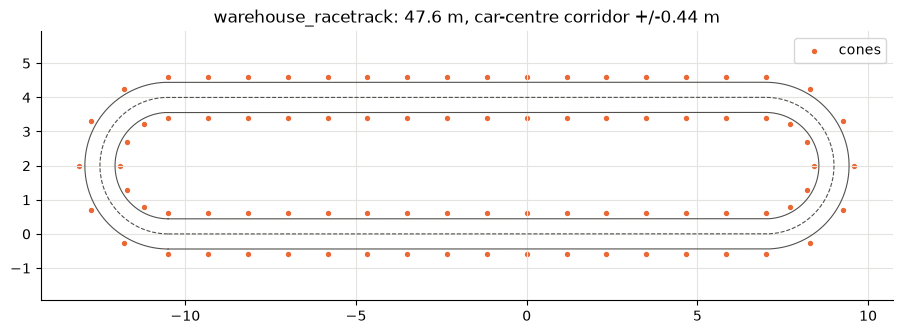

In [2]:
tr = Track.from_world(WS / 'src/middle_earth/worlds/racetrack.world')
h = tr.heading; nx, ny = -np.sin(h), np.cos(h)
plt.figure(figsize=(11, 3.5))
for s in (1, -1):
    plt.plot(tr.xy[:, 0] + s*tr.half_width*nx, tr.xy[:, 1] + s*tr.half_width*ny, color=GREY, lw=0.8)
plt.plot(tr.xy[:, 0], tr.xy[:, 1], color=GREY, ls='--', lw=0.8)
plt.scatter(tr.cones[:, 0], tr.cones[:, 1], s=8, color=ORANGE, label='cones')
plt.axis('equal'); plt.legend(); plt.title(f'{tr.name}: {tr.length:.1f} m, car-centre corridor +/-{tr.half_width:.2f} m'); plt.show()

## 2. A lap-time bound from physics
Grip limits the speed at each point: $v \le \sqrt{\mu g/|\kappa|}$. Acceleration and braking limit how fast
that profile can change: a forward pass with $a$ and a backward pass with $b$ give the fastest feasible
speed along the centreline (racing lines can do slightly better by widening the bends).

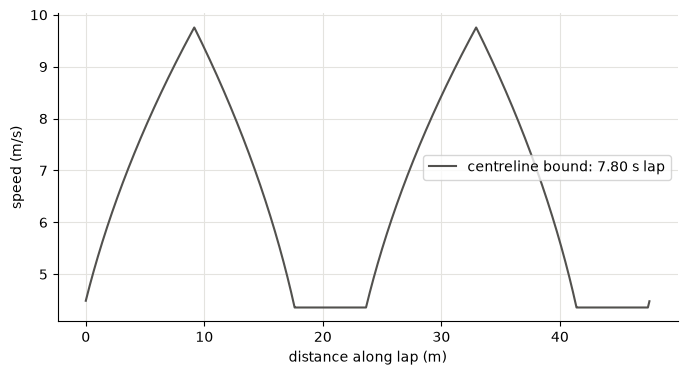

physics bound on the centreline: 7.80 s per flying lap


In [3]:
def speed_profile(track, mu_g=9.5, a=4.1, b=4.5, vmax=12.0):
    ds = np.diff(np.r_[track.s, track.length])
    v = np.minimum(vmax, np.sqrt(mu_g/np.maximum(np.abs(track.curvature), 1e-6)))
    for _ in range(2):                                  # wrap around twice for a flying lap
        for i in range(len(v)): v[i] = min(v[i], np.sqrt(v[i-1]**2 + 2*a*ds[i-1]))
        for i in range(len(v) - 1, -1, -1): v[i] = min(v[i], np.sqrt(v[(i+1) % len(v)]**2 + 2*b*ds[i]))
    return v, np.sum(ds/v)
v_bound, t_bound = speed_profile(tr)
plt.plot(tr.s, v_bound, color=GREY, label=f'centreline bound: {t_bound:.2f} s lap')
plt.xlabel('distance along lap (m)'); plt.ylabel('speed (m/s)'); plt.legend(); plt.show()
print(f'physics bound on the centreline: {t_bound:.2f} s per flying lap')

## 3. Advantage estimation (GAE) by hand

In [4]:
def gae(rewards, values, gamma=0.99, lam=0.95):
    """values has one more entry than rewards (bootstrap value of the final state)."""
    adv, last = np.zeros(len(rewards)), 0.0
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma*values[t+1] - values[t]
        last = delta + gamma*lam*last; adv[t] = last
    return adv
r = np.array([0.1, 0.2, -10.0]); V = np.array([1.0, 1.1, 0.5, 0.0])     # a crash at step 3
print('advantages:', np.round(gae(r, V), 3))

advantages: [ -9.48 -10.28 -10.5 ]


## 4. PPO's clipped objective
For advantage $A$ the per-sample objective is $\min(\rho A, \operatorname{clip}(\rho, 1-\epsilon, 1+\epsilon)A)$.

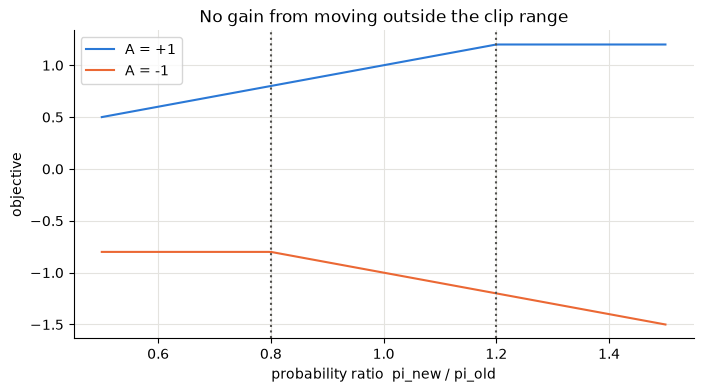

In [5]:
rho = np.linspace(0.5, 1.5, 200); eps = 0.2
for A, c in ((1.0, BLUE), (-1.0, ORANGE)):
    plt.plot(rho, np.minimum(rho*A, np.clip(rho, 1-eps, 1+eps)*A), color=c, label=f'A = {A:+.0f}')
plt.axvline(1-eps, color=GREY, ls=':'); plt.axvline(1+eps, color=GREY, ls=':')
plt.xlabel('probability ratio  pi_new / pi_old'); plt.ylabel('objective'); plt.legend(); plt.title('No gain from moving outside the clip range'); plt.show()

## 5. Driving the environment: baseline vs trained policy

pure pursuit at 1 m/s lap times: [47.7, 95.25]


policy rl_runs/ppo_v1/best_model.zip: lap times [8.35, 15.7], crashed False
policy top speed 9.9 m/s, slowest corner speed 2.9 m/s


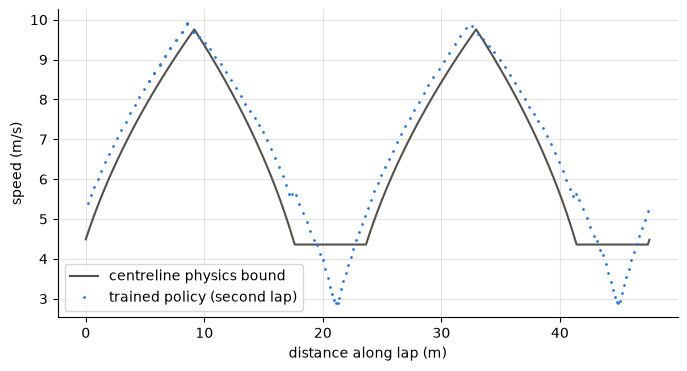

In [6]:
def drive(policy, track_index=0, laps=2):
    env = E.RaceEnv(randomize=False, max_time=200)
    start = env.tracks[track_index].s[env.tracks[track_index].project(-1.127, 0.0)]
    obs, _ = env.reset(options={'track': track_index, 'start_s': start})
    log = []
    while True:
        a = policy(env, obs); obs, _, term, trunc, info = env.step(a)
        log.append((env.track.s[env.i], env.v))
        if term or trunc or info['laps'] >= laps: return np.array(log), info

def pure_pursuit(speed):
    def p(env, obs):
        j = env.track.ahead(env.i, [1.0])[0]; dx, dy = env.track.xy[j] - (env.x, env.y)
        alpha = np.arctan2(dy, dx) - env.yaw; d = np.arctan(2*E.WHEELBASE*np.sin(alpha)/1.0)
        return [speed/E.V_MAX*2 - 1, np.clip(d/E.STEER_MAX, -1, 1)]
    return p

log_pp, info_pp = drive(pure_pursuit(1.0))
print('pure pursuit at 1 m/s lap times:', [round(t, 2) for t in info_pp['lap_times']])
model_path = sorted(WS.glob('rl_runs/*/best_model.zip'))
if model_path:
    from stable_baselines3 import PPO
    model = PPO.load(model_path[-1], device='cpu')
    log_rl, info_rl = drive(lambda env, obs: model.predict(obs, deterministic=True)[0])
    times = info_rl['lap_times']
    print(f'policy {model_path[-1].relative_to(WS)}: lap times {[round(t, 2) for t in times]}, crashed {info_rl["crashed"]}')
    n = len(log_rl)//2; lap2 = log_rl[n:]
    print(f'policy top speed {log_rl[:, 1].max():.1f} m/s, slowest corner speed {lap2[:, 1].min():.1f} m/s')
    plt.plot(tr.s, v_bound, color=GREY, label='centreline physics bound')
    plt.plot(lap2[:, 0], lap2[:, 1], '.', ms=2, color=BLUE, label='trained policy (second lap)')
    plt.xlabel('distance along lap (m)'); plt.ylabel('speed (m/s)'); plt.legend(); plt.show()
else:
    print('No trained policy in rl_runs/ — run python -m saurcon_rl.train first.')

**Reading the plot.** On the straights the policy accelerates earlier and brakes later than the centreline
bound: within the ±0.44 m corridor it can take a wider line through the bend exits and entries. In the bends
themselves it is *slower* than the bound (about 2.9 vs 4.4 m/s). It was trained against grip as low as
8.5 m/s² and up to 0.3 s of steering lag, so it corners for the worst car it might be — the price of
robustness. Overall it still *beats* the centreline bound (7.35 s vs 7.80 s): the wider line gains more on the
straights than the cautious corners lose — a racing line is worth more than driving the centreline perfectly.

## Exercises
1. Increase `mu_g` in `speed_profile` by 10%. How much lap time does that buy? Compare with the trained policy.
2. Plot the policy's lateral offset vs distance. Does it use a classic racing line?
3. Evaluate the policy on `basement.world` in reverse — a track and direction weighted less in training.